##import the libraries 

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.pipeline import Pipeline

In [41]:
# Load prepared datasets
train_df = pd.read_csv(
    r"C:\Users\shahd\Documents\GitHub\ai4i-predictive-maintenance\milestone4\data\train_ready_milestone3.csv"
)

test_df = pd.read_csv(
    r"C:\Users\shahd\Documents\GitHub\ai4i-predictive-maintenance\milestone4\data\test_ready_milestone3.csv"
)

# Separate features and target
X_train = train_df.drop("Machine failure", axis=1)
y_train = train_df["Machine failure"]

X_test = test_df.drop("Machine failure", axis=1)
y_test = test_df["Machine failure"]

In [42]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [43]:
results = []

for name, model in models.items():

    # Validation using 5-fold Cross-Validation
    cv_scores = cross_val_score(
        model, X_train, y_train, cv=20, scoring="accuracy"
    )

    # Train the model using training data
    model.fit(X_train, y_train)

    # Test the model using testing data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Validation Accuracy": cv_scores.mean(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

# Compare model performance
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(results_df.round(4))

,Model,Validation Accuracy,Accuracy,Recall,F1-score
3,Random Forest,0.9731,0.9720,0.9102,0.9366
4,Gradient Boosting,0.9678,0.9668,0.8820,0.9235
2,Decision Tree,0.9514,0.9460,0.8803,0.8811
1,KNN,0.9412,0.9356,0.7553,0.8420
0,Logistic Regression,0.8314,0.8332,0.3539,0.4908


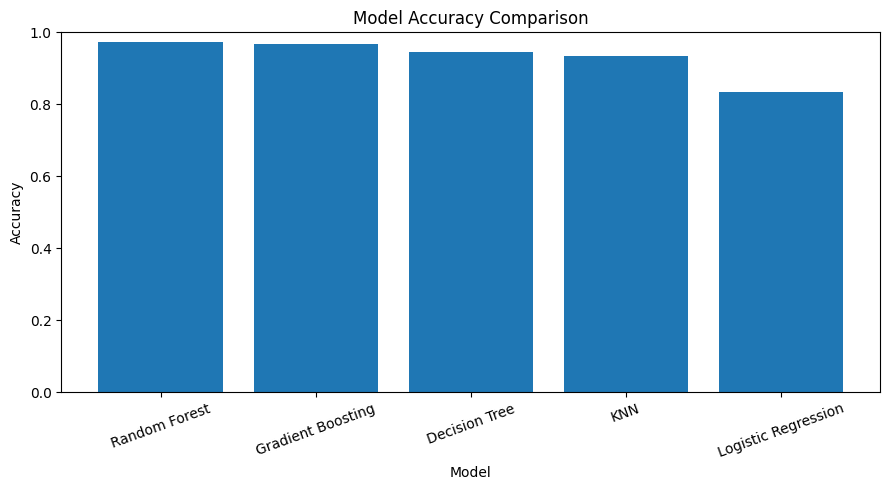

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()